# Brain tumor segmentation with UNet and UNet++

**Task:** mark the tumor in brain MRI images.

**Data:** the Figshare brain tumor dataset (Cheng et al., 2015). It has about 3,000 MRI slices from 233 patients, each with a tumor mask. The tumors are meningioma, glioma or pituitary tumors. We load it from a copy on Hugging Face, which needs no account.

**Plan:**
1. Load the data
2. Build UNet and UNet++
3. Train both the same way
4. Compare them with the Dice score

**Use a GPU.** On Colab, choose *Runtime → Change runtime type → T4 GPU* before running. The first code cell prints `device: cuda` when the GPU is on. Training on a CPU is many times slower.

## 1. Setup

In [1]:
# !pip install datasets   # uncomment if 'datasets' is not installed

import os
import time

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from datasets import load_dataset
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
if device == "cpu":
    print("No GPU found. Training will be slow; switch the runtime to a GPU if you can.")

IMAGE_SIZE = 256
BASE_CHANNELS = 32   # width of the first layer; 32 is more accurate but about 4x slower
BATCH_SIZE = 16
EPOCHS = 20
LEARNING_RATE = 1e-3

if os.environ.get("SMOKE_TEST") == "1":   # quick test run
    EPOCHS = 2

torch.manual_seed(0)
np.random.seed(0)

device: cuda


## 2. Load the data

In [2]:
dataset = load_dataset("MedOtter/Figshare_Brain_Tumor")
print(dataset)

README.md:   0%|          | 0.00/3.23k [00:00<?, ?B/s]

data/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  191MB            

data/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  194MB            

data/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  206MB            

... (2 outputs left out)

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'pid', 'label_id', 'label_name', 'fold', 'image', 'mask', 'tumor_border'],
        num_rows: 2522
    })
    test: Dataset({
        features: ['id', 'pid', 'label_id', 'label_name', 'fold', 'image', 'mask', 'tumor_border'],
        num_rows: 542
    })
})


Every image is resized to 128x128 and scaled to the range 0–1. The MRI images are grayscale, so each has one channel. The masks are JPG files, so their values are not exactly 0 and 255; anything above 127 counts as tumor.

In [3]:
def to_tensors(split):
    images, masks = [], []
    for row in split:
        image = row["image"].resize((IMAGE_SIZE, IMAGE_SIZE))
        image = np.array(image, dtype=np.float32)
        if image.ndim == 3:            # in case an image is stored as RGB
            image = image.mean(axis=2)
        image = image / max(image.max(), 1)

        mask = row["mask"].convert("L").resize((IMAGE_SIZE, IMAGE_SIZE), Image.NEAREST)
        mask = np.array(mask) > 127

        images.append(image)
        masks.append(mask)

    images = torch.tensor(np.array(images), dtype=torch.float32).unsqueeze(1)  # (N, 1, H, W)
    masks = torch.tensor(np.array(masks), dtype=torch.float32).unsqueeze(1)    # (N, 1, H, W)
    return images, masks


train_images, train_masks = to_tensors(dataset["train"])
test_images, test_masks = to_tensors(dataset["test"])
print("train:", len(train_images), " test:", len(test_images))

train: 2522  test: 542


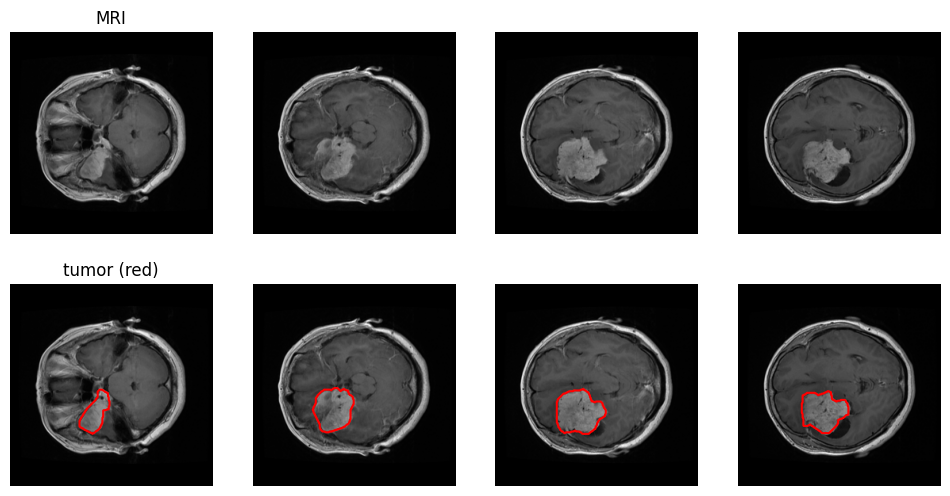

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i in range(4):
    axes[0, i].imshow(train_images[i, 0], cmap="gray")
    axes[1, i].imshow(train_images[i, 0], cmap="gray")
    axes[1, i].contour(train_masks[i, 0], levels=[0.5], colors="red")
    axes[0, i].axis("off")
    axes[1, i].axis("off")
axes[0, 0].set_title("MRI")
axes[1, 0].set_title("tumor (red)")
plt.show()

In [5]:
class BrainDataset(Dataset):
    def __init__(self, images, masks, augment=False):
        self.images = images
        self.masks = masks
        self.augment = augment

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        image = self.images[i]
        mask = self.masks[i]
        if self.augment and np.random.rand() < 0.5:   # left-right flip
            image, mask = image.flip(2), mask.flip(2)
        return image, mask


train_loader = DataLoader(BrainDataset(train_images, train_masks, augment=True), batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(BrainDataset(test_images, test_masks), batch_size=BATCH_SIZE)

## 3. Models

Both models are built from the same block: two 3x3 convolutions, each followed by batch norm and ReLU.

**UNet:** the encoder makes the image smaller step by step, and the decoder makes it bigger again. Skip connections copy encoder features directly to the decoder.

**UNet++:** the skip connections pass through extra conv blocks first. This makes the encoder and decoder features more alike before they are joined.

In [6]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.conv(x)


def down(x):
    return F.max_pool2d(x, 2)


def up(x):
    return F.interpolate(x, scale_factor=2, mode="bilinear")

In [7]:
class UNet(nn.Module):
    def __init__(self, base=16):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]

        self.enc0 = ConvBlock(1, c[0])
        self.enc1 = ConvBlock(c[0], c[1])
        self.enc2 = ConvBlock(c[1], c[2])
        self.enc3 = ConvBlock(c[2], c[3])
        self.bottom = ConvBlock(c[3], c[4])

        self.dec3 = ConvBlock(c[4] + c[3], c[3])
        self.dec2 = ConvBlock(c[3] + c[2], c[2])
        self.dec1 = ConvBlock(c[2] + c[1], c[1])
        self.dec0 = ConvBlock(c[1] + c[0], c[0])

        self.out = nn.Conv2d(c[0], 1, 1)

    def forward(self, x):
        e0 = self.enc0(x)
        e1 = self.enc1(down(e0))
        e2 = self.enc2(down(e1))
        e3 = self.enc3(down(e2))
        b = self.bottom(down(e3))

        d3 = self.dec3(torch.cat([up(b), e3], dim=1))
        d2 = self.dec2(torch.cat([up(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([up(d2), e1], dim=1))
        d0 = self.dec0(torch.cat([up(d1), e0], dim=1))
        return self.out(d0)

In [8]:
class UNetPlusPlus(nn.Module):
    # x_i_j: i = level (0 is full size), j = position along the skip path
    def __init__(self, base=16):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]

        self.x0_0 = ConvBlock(1, c[0])
        self.x1_0 = ConvBlock(c[0], c[1])
        self.x2_0 = ConvBlock(c[1], c[2])
        self.x3_0 = ConvBlock(c[2], c[3])
        self.x4_0 = ConvBlock(c[3], c[4])

        self.x0_1 = ConvBlock(c[0] + c[1], c[0])
        self.x1_1 = ConvBlock(c[1] + c[2], c[1])
        self.x2_1 = ConvBlock(c[2] + c[3], c[2])
        self.x3_1 = ConvBlock(c[3] + c[4], c[3])

        self.x0_2 = ConvBlock(c[0] * 2 + c[1], c[0])
        self.x1_2 = ConvBlock(c[1] * 2 + c[2], c[1])
        self.x2_2 = ConvBlock(c[2] * 2 + c[3], c[2])

        self.x0_3 = ConvBlock(c[0] * 3 + c[1], c[0])
        self.x1_3 = ConvBlock(c[1] * 3 + c[2], c[1])

        self.x0_4 = ConvBlock(c[0] * 4 + c[1], c[0])

        self.out = nn.Conv2d(c[0], 1, 1)

    def forward(self, x):
        x0_0 = self.x0_0(x)
        x1_0 = self.x1_0(down(x0_0))
        x0_1 = self.x0_1(torch.cat([x0_0, up(x1_0)], 1))

        x2_0 = self.x2_0(down(x1_0))
        x1_1 = self.x1_1(torch.cat([x1_0, up(x2_0)], 1))
        x0_2 = self.x0_2(torch.cat([x0_0, x0_1, up(x1_1)], 1))

        x3_0 = self.x3_0(down(x2_0))
        x2_1 = self.x2_1(torch.cat([x2_0, up(x3_0)], 1))
        x1_2 = self.x1_2(torch.cat([x1_0, x1_1, up(x2_1)], 1))
        x0_3 = self.x0_3(torch.cat([x0_0, x0_1, x0_2, up(x1_2)], 1))

        x4_0 = self.x4_0(down(x3_0))
        x3_1 = self.x3_1(torch.cat([x3_0, up(x4_0)], 1))
        x2_2 = self.x2_2(torch.cat([x2_0, x2_1, up(x3_1)], 1))
        x1_3 = self.x1_3(torch.cat([x1_0, x1_1, x1_2, up(x2_2)], 1))
        x0_4 = self.x0_4(torch.cat([x0_0, x0_1, x0_2, x0_3, up(x1_3)], 1))

        return self.out(x0_4)

In [9]:
for model in [UNet(BASE_CHANNELS), UNetPlusPlus(BASE_CHANNELS)]:
    n_params = sum(p.numel() for p in model.parameters()) / 1e6
    output = model(torch.randn(1, 1, IMAGE_SIZE, IMAGE_SIZE))
    print(f"{type(model).__name__}: output {tuple(output.shape)}, {n_params:.1f}M parameters")

UNet: output (1, 1, 256, 256), 7.9M parameters
UNetPlusPlus: output (1, 1, 256, 256), 9.2M parameters


## 4. Loss and Dice score

- **Loss:** binary cross-entropy + Dice loss
- **Dice score:** overlap between the predicted mask and the true mask, from 0 (no overlap) to 1 (perfect)

In [10]:
def loss_fn(logits, target):
    bce = F.binary_cross_entropy_with_logits(logits, target)
    prob = torch.sigmoid(logits)
    dice = (2 * (prob * target).sum() + 1) / (prob.sum() + target.sum() + 1)
    return bce + (1 - dice)


def dice_score(pred, target):
    # pred and target are 0/1 masks for one image
    total = pred.sum() + target.sum()
    if total == 0:
        return 1.0
    return (2 * (pred * target).sum() / total).item()


@torch.no_grad()
def evaluate(model):
    model.eval()
    scores = []
    for image, mask in test_loader:
        pred = (torch.sigmoid(model(image.to(device))) > 0.5).float().cpu()
        for p, m in zip(pred, mask):
            scores.append(dice_score(p, m))
    return np.mean(scores)

## 5. Training

In [11]:
def train(model):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = {"loss": [], "dice": []}

    for epoch in range(EPOCHS):
        start = time.time()
        model.train()
        total_loss = 0
        for image, mask in train_loader:
            image, mask = image.to(device), mask.to(device)
            loss = loss_fn(model(image), mask)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        test_dice = evaluate(model)
        history["loss"].append(total_loss / len(train_loader))
        history["dice"].append(test_dice)
        print(f"epoch {epoch + 1}/{EPOCHS}  loss {history['loss'][-1]:.4f}  "
              f"test dice {test_dice:.4f}  ({time.time() - start:.0f} s)")

    return model, history

In [12]:
print("UNet")
torch.manual_seed(0)
unet, unet_history = train(UNet(BASE_CHANNELS))

print("\nUNet++")
torch.manual_seed(0)
unetpp, unetpp_history = train(UNetPlusPlus(BASE_CHANNELS))

UNet
epoch 1/20  loss 1.1228  test dice 0.1401  (63 s)
epoch 2/20  loss 0.7157  test dice 0.2284  (62 s)
epoch 3/20  loss 0.5521  test dice 0.4633  (62 s)
epoch 4/20  loss 0.5219  test dice 0.4108  (62 s)
epoch 5/20  loss 0.4675  test dice 0.3649  (62 s)
epoch 6/20  loss 0.4479  test dice 0.5052  (62 s)
epoch 7/20  loss 0.4254  test dice 0.5297  (62 s)
epoch 8/20  loss 0.4140  test dice 0.5544  (62 s)
epoch 9/20  loss 0.3922  test dice 0.5337  (62 s)
epoch 10/20  loss 0.3718  test dice 0.4208  (62 s)
epoch 11/20  loss 0.3542  test dice 0.2807  (62 s)
epoch 12/20  loss 0.3423  test dice 0.5738  (62 s)
epoch 13/20  loss 0.3341  test dice 0.6126  (62 s)
epoch 14/20  loss 0.3120  test dice 0.4808  (62 s)
epoch 15/20  loss 0.3076  test dice 0.6170  (62 s)
epoch 16/20  loss 0.2927  test dice 0.6719  (62 s)
epoch 17/20  loss 0.2936  test dice 0.6129  (62 s)
epoch 18/20  loss 0.2813  test dice 0.5818  (62 s)
epoch 19/20  loss 0.2661  test dice 0.6952  (62 s)
epoch 20/20  loss 0.2589  test dice

## 6. Results

UNet   test dice: 0.6290
UNet++ test dice: 0.6700


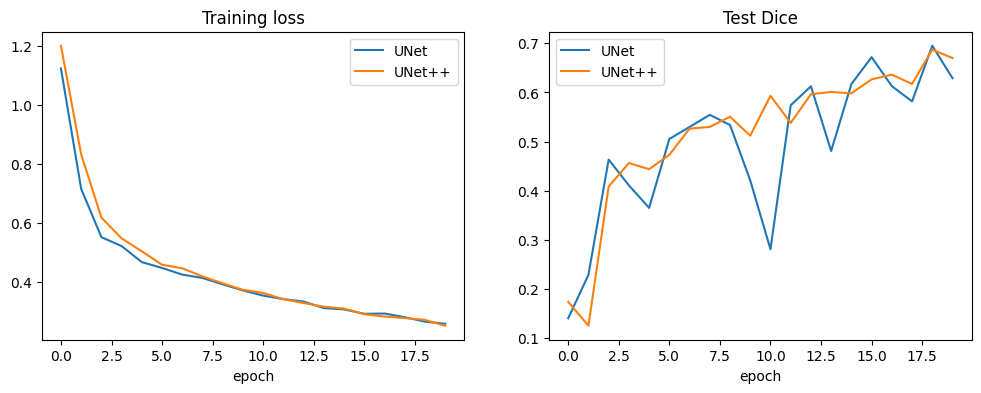

In [13]:
print(f"UNet   test dice: {unet_history['dice'][-1]:.4f}")
print(f"UNet++ test dice: {unetpp_history['dice'][-1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(unet_history["loss"], label="UNet")
axes[0].plot(unetpp_history["loss"], label="UNet++")
axes[0].set_title("Training loss")
axes[1].plot(unet_history["dice"], label="UNet")
axes[1].plot(unetpp_history["dice"], label="UNet++")
axes[1].set_title("Test Dice")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.legend()
plt.show()

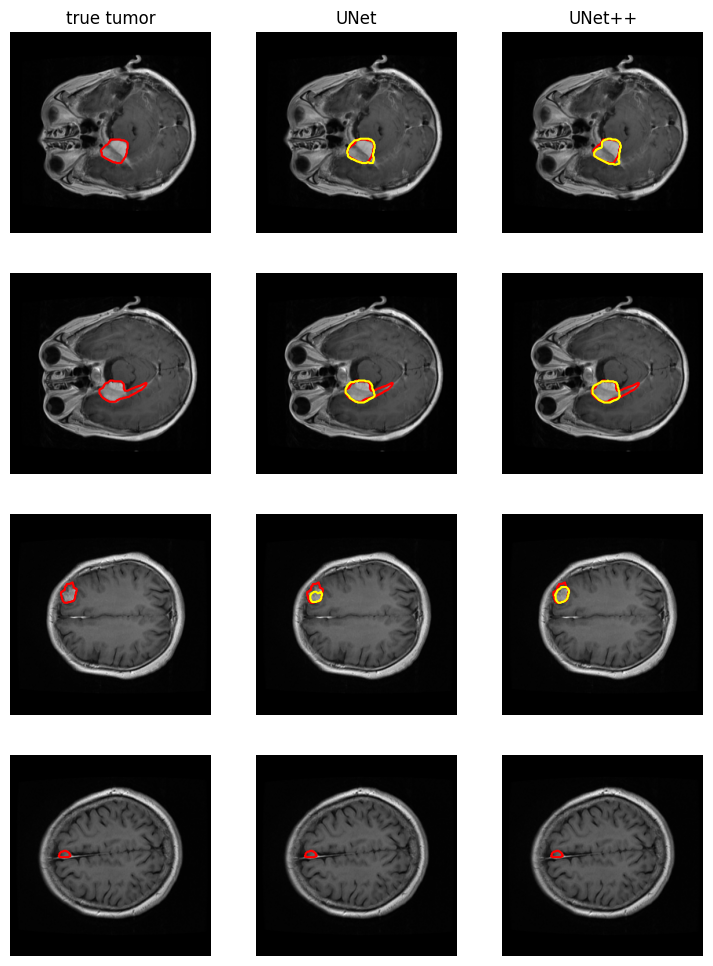

In [14]:
# predictions on 4 test images: red = true tumor, yellow = prediction
unet.eval()
unetpp.eval()
fig, axes = plt.subplots(4, 3, figsize=(9, 12))
for row in range(4):
    image, mask = test_images[row], test_masks[row]
    with torch.no_grad():
        pred_unet = torch.sigmoid(unet(image[None].to(device)))[0, 0].cpu() > 0.5
        pred_unetpp = torch.sigmoid(unetpp(image[None].to(device)))[0, 0].cpu() > 0.5

    for col, pred in enumerate([None, pred_unet, pred_unetpp]):
        axes[row, col].imshow(image[0], cmap="gray")
        axes[row, col].contour(mask[0], levels=[0.5], colors="red")
        if pred is not None:
            axes[row, col].contour(pred.float(), levels=[0.5], colors="yellow")
        axes[row, col].axis("off")

for col, title in enumerate(["true tumor", "UNet", "UNet++"]):
    axes[0, col].set_title(title)
plt.show()